# Import Needed Libraries

In [175]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline

from scipy.stats import zscore

# Dataset Reading

In [176]:
df_raw = pd.read_csv("heart_attack_prediction_indonesia.csv")
df_raw.shape

(158355, 28)

Dataset ini terdiri dari 158.355 baris data dan 28 variables

In [177]:
df_raw.head()

,age,gender,region,income_level,hypertension,diabetes,cholesterol_level,obesity,waist_circumference,family_history,...,blood_pressure_diastolic,fasting_blood_sugar,cholesterol_hdl,cholesterol_ldl,triglycerides,EKG_results,previous_heart_disease,medication_usage,participated_in_free_screening,heart_attack
0,60,Male,Rural,Middle,0,1,211,0,83,0,...,62,173,48,121,101,Normal,0,0,0,0
1,53,Female,Urban,Low,0,0,208,0,106,1,...,76,70,58,83,138,Normal,1,0,1,0
2,62,Female,Urban,Low,0,0,231,1,112,1,...,74,118,69,130,171,Abnormal,0,1,0,1
3,73,Male,Urban,Low,1,0,202,0,82,1,...,65,98,52,85,146,Normal,0,1,1,0
4,52,Male,Urban,Middle,1,0,232,0,89,0,...,75,104,59,127,139,Normal,1,0,1,1


# Data Pre-Processing

In [178]:
df = df_raw.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158355 entries, 0 to 158354
Data columns (total 28 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   age                             158355 non-null  int64  
 1   gender                          158355 non-null  object 
 2   region                          158355 non-null  object 
 3   income_level                    158355 non-null  object 
 4   hypertension                    158355 non-null  int64  
 5   diabetes                        158355 non-null  int64  
 6   cholesterol_level               158355 non-null  int64  
 7   obesity                         158355 non-null  int64  
 8   waist_circumference             158355 non-null  int64  
 9   family_history                  158355 non-null  int64  
 10  smoking_status                  158355 non-null  object 
 11  alcohol_consumption             63507 non-null   object 
 12  physical_activit

In [179]:
# Descriptive Statistics

df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,158355.0,54.543778,11.910897,25.0,46.000000,55.000000,63.00000,90.0
hypertension,158355.0,0.299069,0.457851,0.0,0.000000,0.000000,1.00000,1.0
diabetes,158355.0,0.199804,0.399854,0.0,0.000000,0.000000,0.00000,1.0
cholesterol_level,158355.0,199.533264,39.737565,100.0,172.000000,199.000000,226.00000,350.0
obesity,158355.0,0.249901,0.432957,0.0,0.000000,0.000000,0.00000,1.0
waist_circumference,158355.0,93.268504,16.382205,20.0,82.000000,93.000000,104.00000,173.0
family_history,158355.0,0.300218,0.458354,0.0,0.000000,0.000000,1.00000,1.0
sleep_hours,158355.0,6.480064,1.425398,3.0,5.492985,6.507461,7.52064,9.0
blood_pressure_systolic,158355.0,129.515772,15.005641,61.0,119.000000,130.000000,140.00000,199.0
blood_pressure_diastolic,158355.0,79.490809,10.002964,37.0,73.000000,80.000000,86.00000,127.0


## Data Cleaning

In [180]:
print(df['alcohol_consumption'].unique())

[nan 'Moderate' 'High']


memeriksa unique value sebelum handling missing value

In [181]:
# Check Missing Values

(df.isna().sum() / len(df) * 100).sort_values(ascending=False)

alcohol_consumption               59.895804
age                                0.000000
stress_level                       0.000000
participated_in_free_screening     0.000000
medication_usage                   0.000000
previous_heart_disease             0.000000
EKG_results                        0.000000
triglycerides                      0.000000
cholesterol_ldl                    0.000000
cholesterol_hdl                    0.000000
fasting_blood_sugar                0.000000
blood_pressure_diastolic           0.000000
blood_pressure_systolic            0.000000
sleep_hours                        0.000000
air_pollution_exposure             0.000000
gender                             0.000000
dietary_habits                     0.000000
physical_activity                  0.000000
smoking_status                     0.000000
family_history                     0.000000
waist_circumference                0.000000
obesity                            0.000000
cholesterol_level               

In [182]:
# Handling Missing Value

# melihat distribusi data 'alcohol_consumption' sebelum filling missing value
print(df['alcohol_consumption'].value_counts(normalize=True))

alcohol_consumption
Moderate    0.751492
High        0.248508
Name: proportion, dtype: float64


In [183]:
def fill_alcohol_na():
    return np.random.choice(['Moderate', 'High'], p=[0.75, 0.25])

df['alcohol_consumption'] = df['alcohol_consumption'].apply(
    lambda x: fill_alcohol_na() if pd.isna(x) else x
)

In [184]:
df['alcohol_consumption'] = df['alcohol_consumption'].apply(str)

In [185]:
#melihat distribusi data 'alcohol_consumption' setelah filling missing value

print(df['alcohol_consumption'].value_counts(normalize=True))

alcohol_consumption
Moderate    0.751722
High        0.248278
Name: proportion, dtype: float64


In [186]:
#final check missing value

(df.isna().sum() / len(df) * 100).sort_values(ascending=False)

age                               0.0
gender                            0.0
participated_in_free_screening    0.0
medication_usage                  0.0
previous_heart_disease            0.0
EKG_results                       0.0
triglycerides                     0.0
cholesterol_ldl                   0.0
cholesterol_hdl                   0.0
fasting_blood_sugar               0.0
blood_pressure_diastolic          0.0
blood_pressure_systolic           0.0
sleep_hours                       0.0
stress_level                      0.0
air_pollution_exposure            0.0
dietary_habits                    0.0
physical_activity                 0.0
alcohol_consumption               0.0
smoking_status                    0.0
family_history                    0.0
waist_circumference               0.0
obesity                           0.0
cholesterol_level                 0.0
diabetes                          0.0
hypertension                      0.0
income_level                      0.0
region      

In [187]:
# final check unique value

print(df['alcohol_consumption'].unique())

['Moderate' 'High']


In [188]:
# Check duplicate

print(df.duplicated().sum())

0


Terlihat tidak ada duplicate data di dataset ini

In [189]:
# menentukan kolom kategorik untuk melakukan encoding

ordinal_cols = ['income_level', 'stress_level', 'alcohol_consumption']
nominal_cols = ['gender', 'region', 'dietary_habits', 'physical_activity',
                'air_pollution_exposure', 'smoking_status', 'EKG_results']
numeric_cols = ['age', 'waist_circumference', 'sleep_hours',
                'blood_pressure_systolic', 'blood_pressure_diastolic',
                'fasting_blood_sugar', 'cholesterol_hdl', 'cholesterol_ldl',
                'triglycerides']
target_col = 'heart_attack'

In [190]:
# Pisah kolom fitur dan target

X = df.drop(columns=[target_col])
y = df[target_col]

In [191]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [192]:
# Outlier detection di data train
scaler_num = StandardScaler()
X_train_num_scaled = scaler_num.fit_transform(X_train[numeric_cols])

z_scores_train  = np.abs(zscore(X_train_num_scaled))
outliers_train = (z_scores_train > 3).any(axis=1)
print(outliers_train.sum())

2232


In [193]:
# Removing Outlier di data train
X_train_clean = X_train.loc[~outliers_train].reset_index(drop=True)
y_train_clean = y_train.loc[~outliers_train].reset_index(drop=True)

In [194]:
# preprocessing pipeline
preprocessor = ColumnTransformer([
    ('ordinal', OrdinalEncoder(), ordinal_cols),
    ('nominal', OneHotEncoder(drop='first'), nominal_cols),
    ('numeric', StandardScaler(), numeric_cols)
], remainder='passthrough')

In [195]:
# Fit preprocessing di train bersih dan transform train + test
X_train_processed = preprocessor.fit_transform(X_train_clean)
X_test_processed = preprocessor.transform(X_test)

In [196]:
ordinal_names = ordinal_cols
nominal_names = preprocessor.named_transformers_['nominal'].get_feature_names_out(nominal_cols).tolist()
numeric_names = numeric_cols
other_cols = [col for col in X.columns if col not in ordinal_cols + nominal_cols + numeric_cols]

all_columns = ordinal_names + nominal_names + numeric_names + other_cols

X_train_df = pd.DataFrame(X_train_processed, columns=all_columns)
X_test_df = pd.DataFrame(X_test_processed, columns=all_columns)

print("Shape X_train_df:", X_train_df.shape)
print("Shape X_test_df:", X_test_df.shape)
print("Shape y_train_clean:", y_train_clean.shape[0])
print("Shape y_test:", y_test.shape[0])

Shape X_train_df: (124452, 30)
Shape X_test_df: (31671, 30)
Shape y_train_clean: 124452
Shape y_test: 31671


---------------------------------------------------

# Exploratory Data Analysis (EDA)

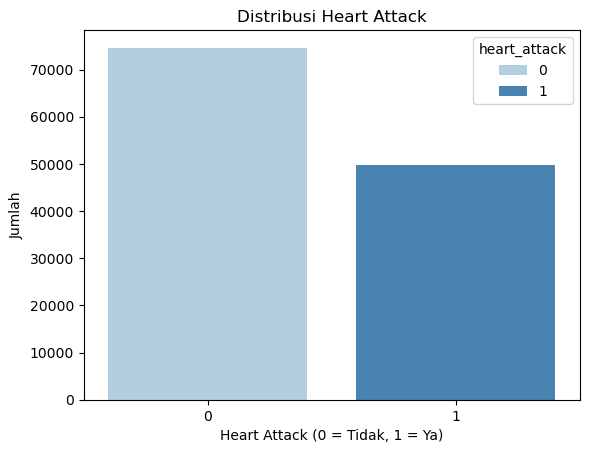

heart_attack
0    0.599653
1    0.400347
Name: proportion, dtype: float64


In [197]:
# Distribusi target
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=y_train_clean, palette='Blues', hue=y_train_clean)
plt.title("Distribusi Heart Attack")
plt.xlabel("Heart Attack (0 = Tidak, 1 = Ya)")
plt.ylabel("Jumlah")
plt.show()

print(y_train_clean.value_counts(normalize=True))



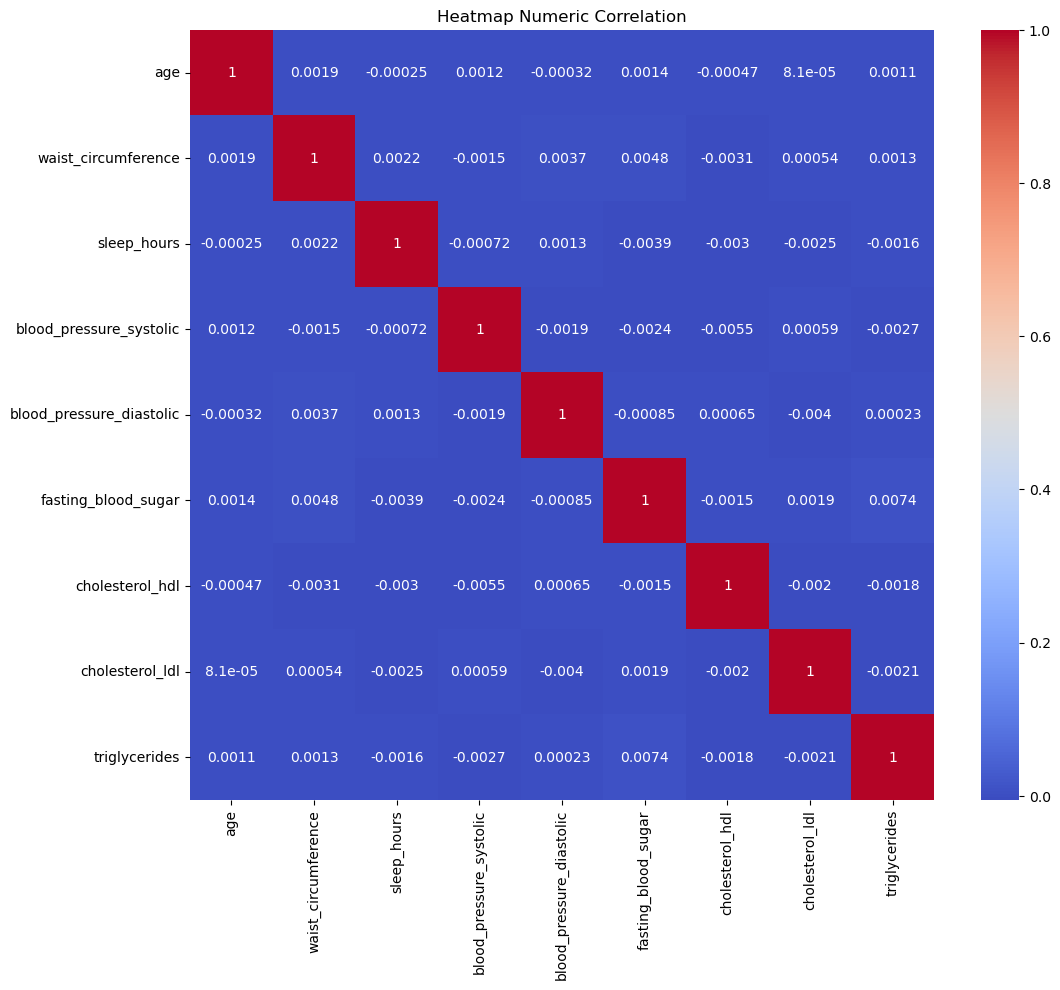

In [198]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train_df[numeric_names].corr(), annot=True, cmap='coolwarm')
plt.title("Heatmap Numeric Correlation")
plt.show()


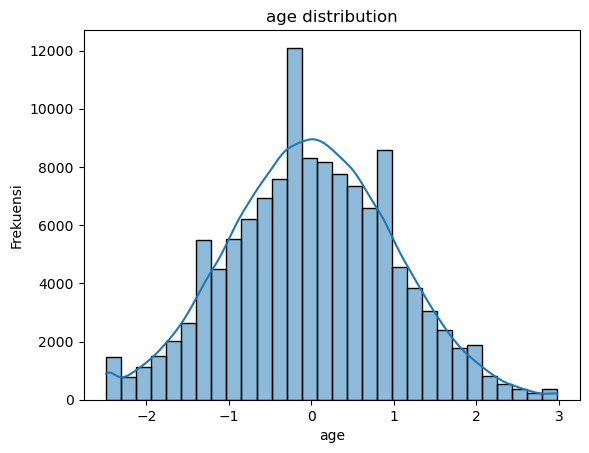

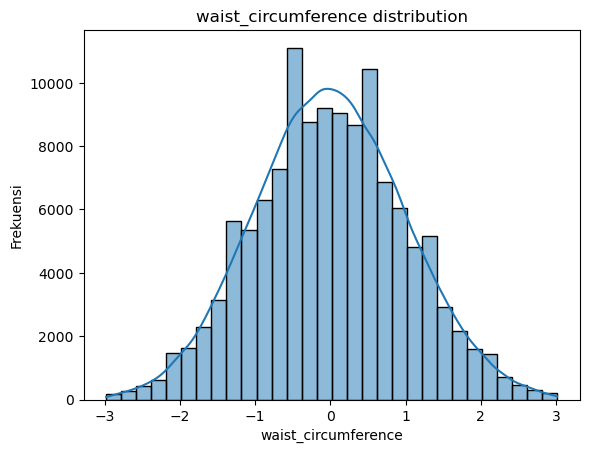

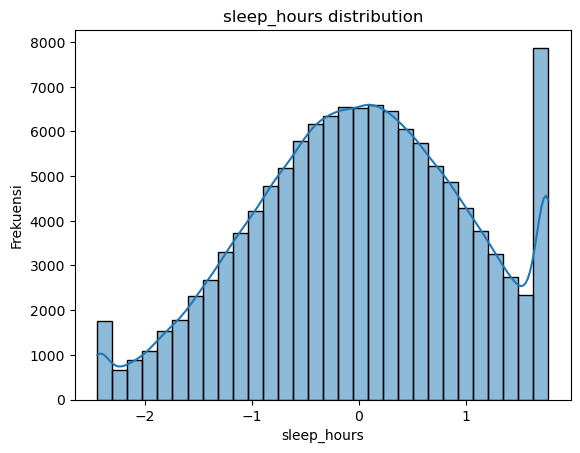

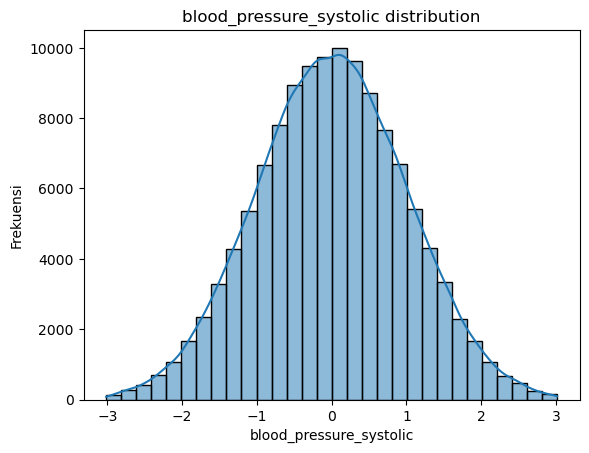

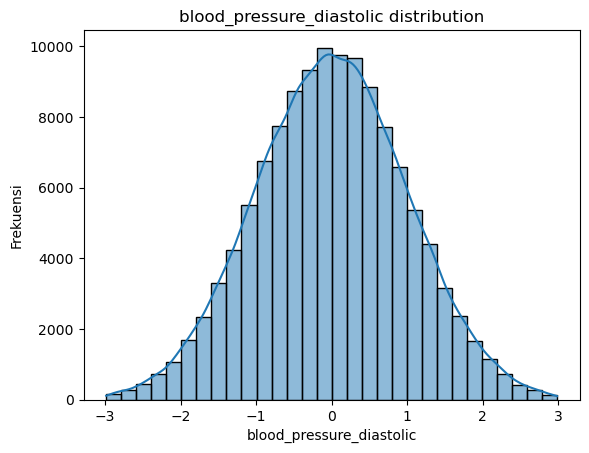

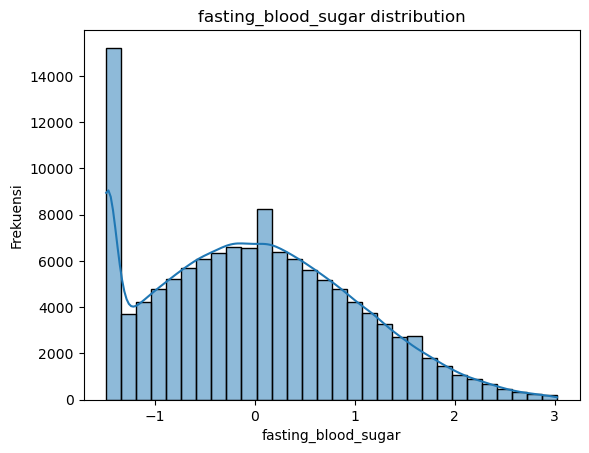

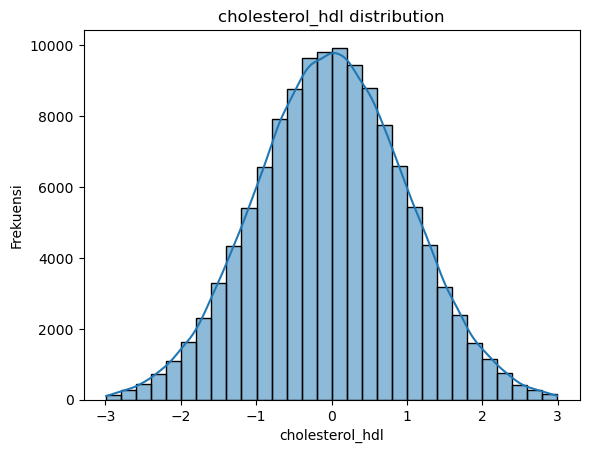

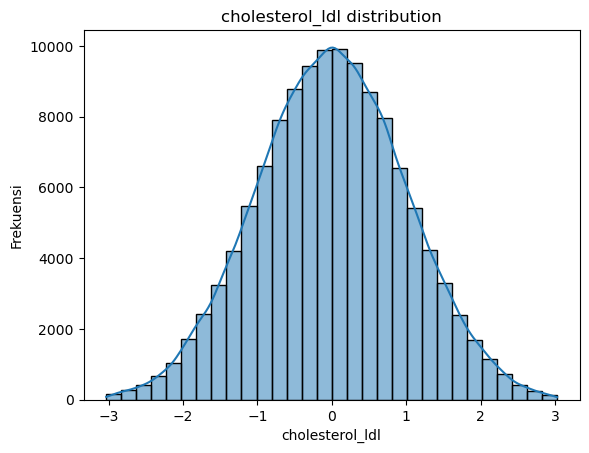

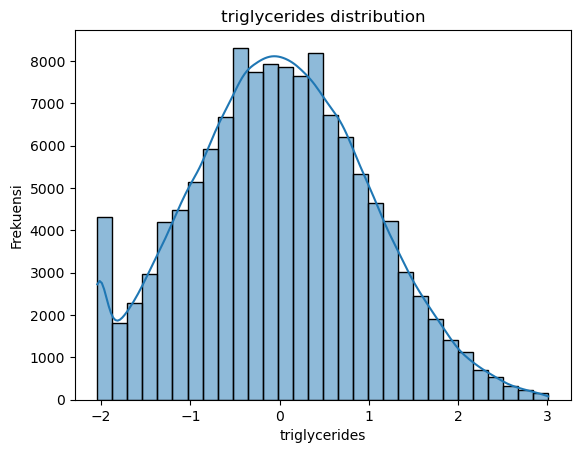

In [199]:
# Distribusi setiap fitur numerik
for col in numeric_names:
    plt.figure()
    sns.histplot(X_train_df[col], kde=True, bins=30)
    plt.title(f"{col} distribution")
    plt.xlabel(col)
    plt.ylabel("Frekuensi")
    plt.show()

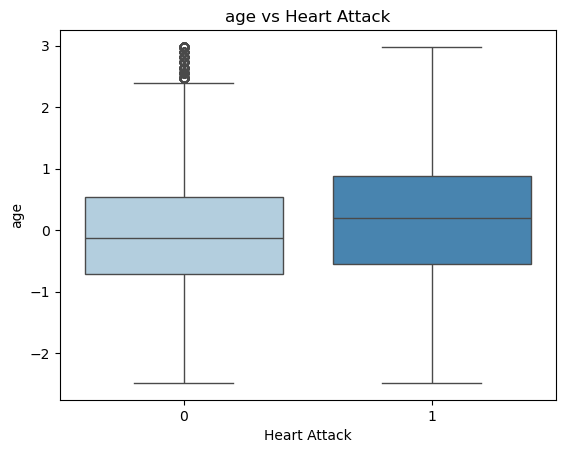

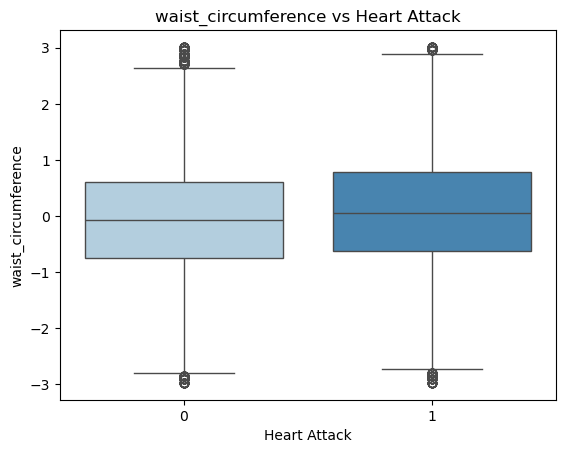

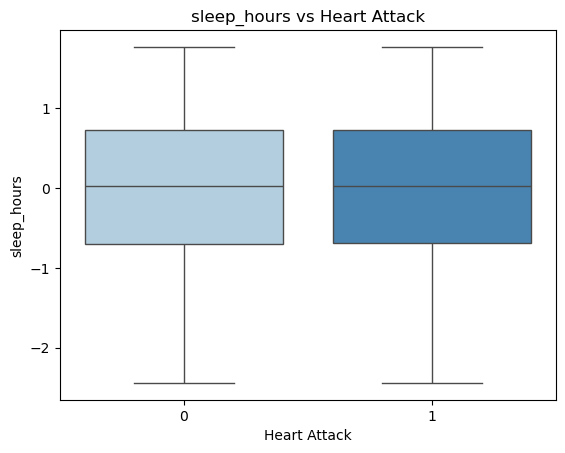

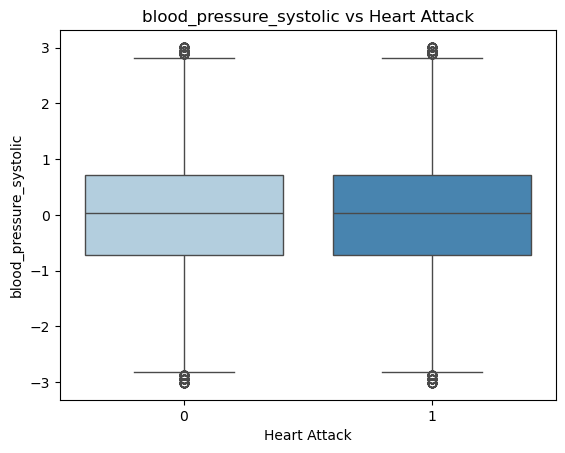

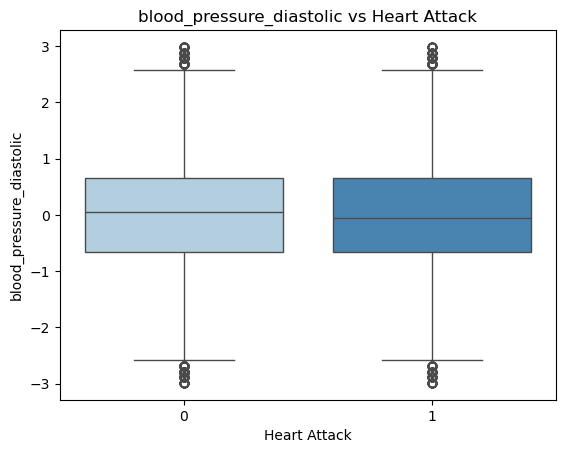

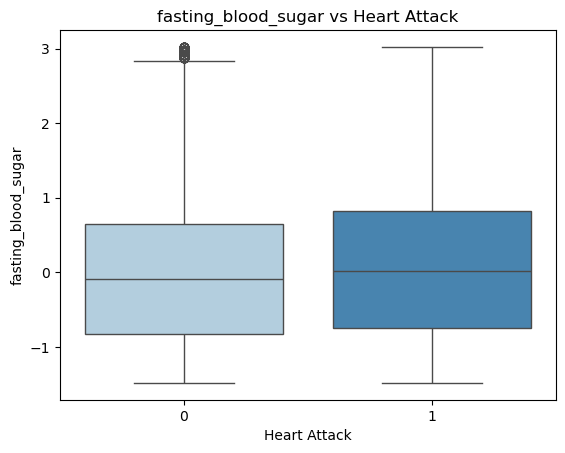

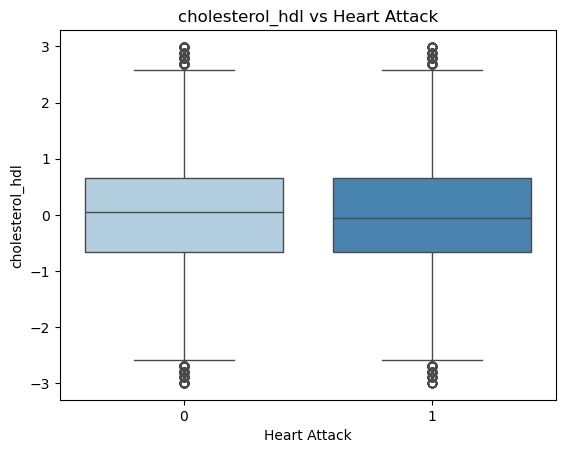

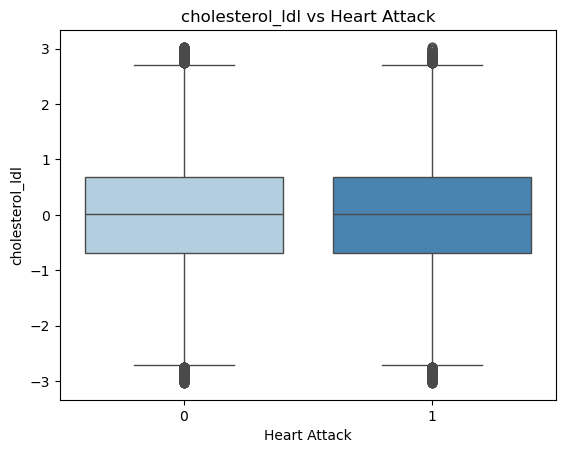

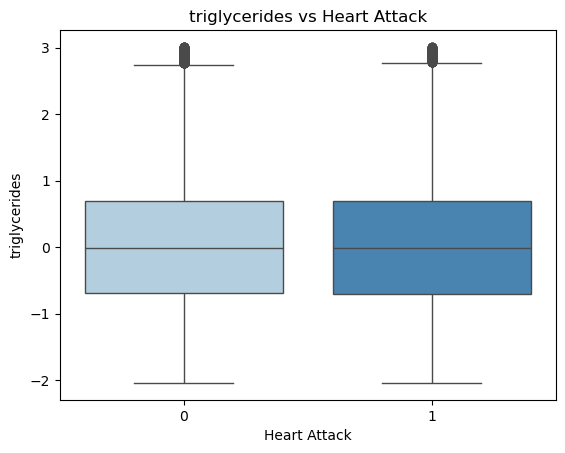

In [200]:
X_train_df['heart_attack'] = y_train_clean.values
for col in numeric_names:
    plt.figure()
    sns.boxplot(x='heart_attack', y=col,
                data=X_train_df,
                palette='Blues',
                hue='heart_attack',
                legend=False)
    plt.title(f"{col} vs Heart Attack")
    plt.xlabel("Heart Attack")
    plt.ylabel(col)
    plt.show()

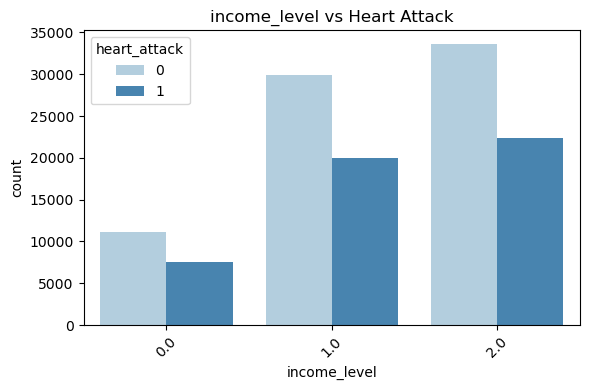

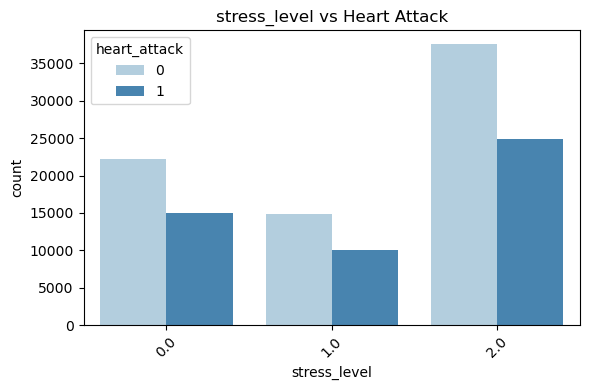

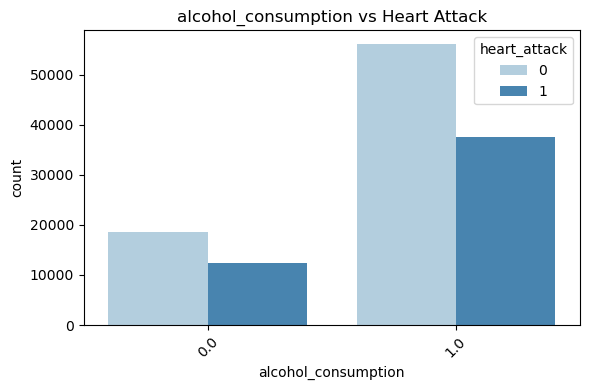

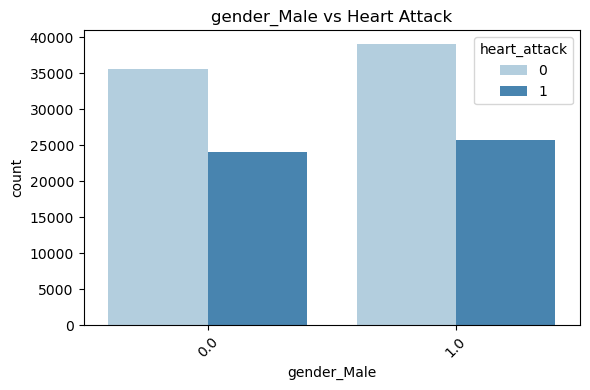

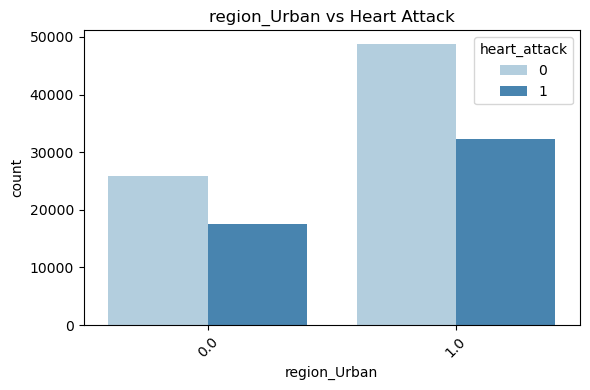

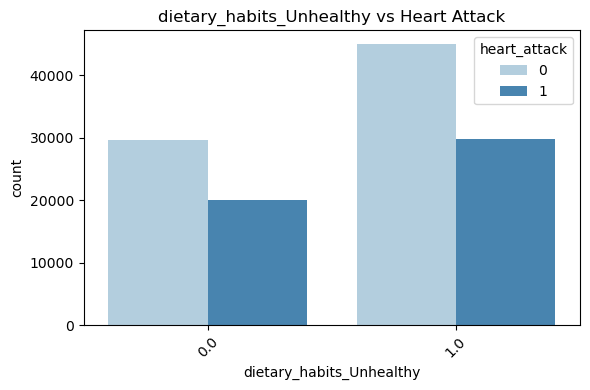

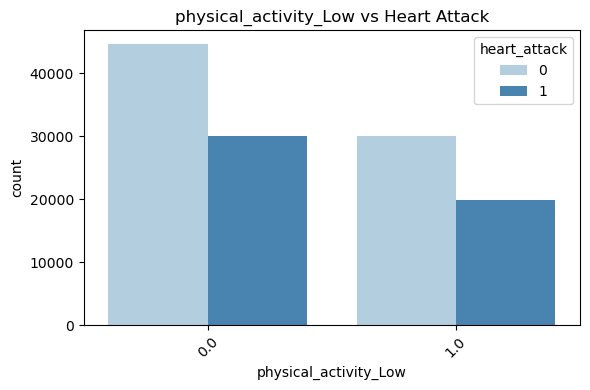

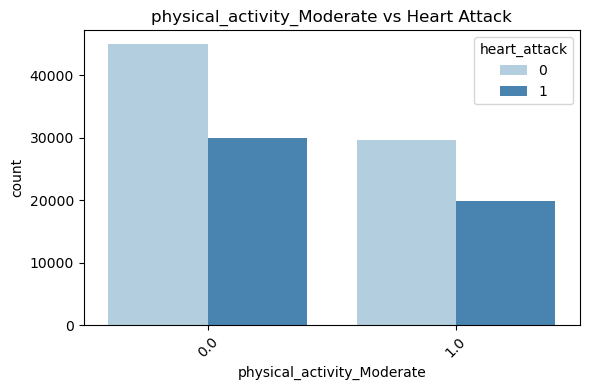

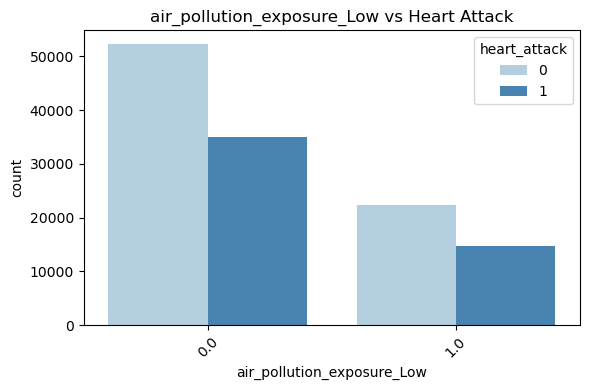

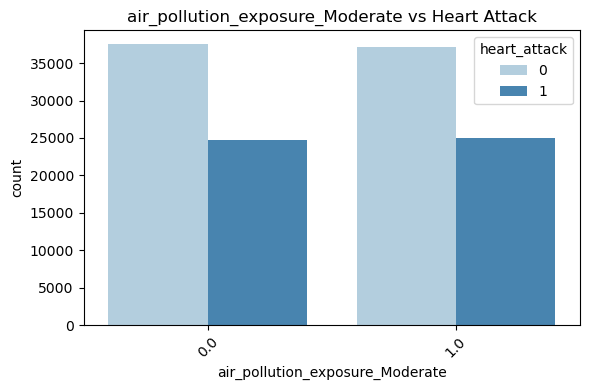

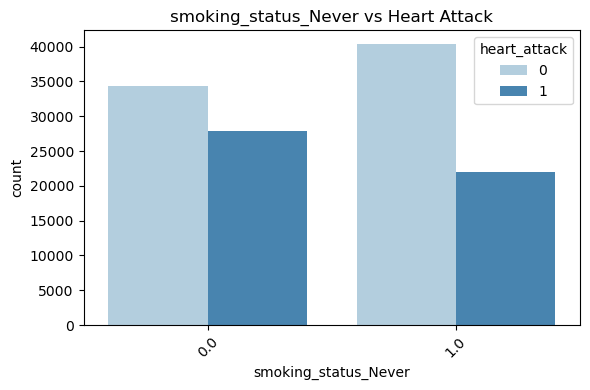

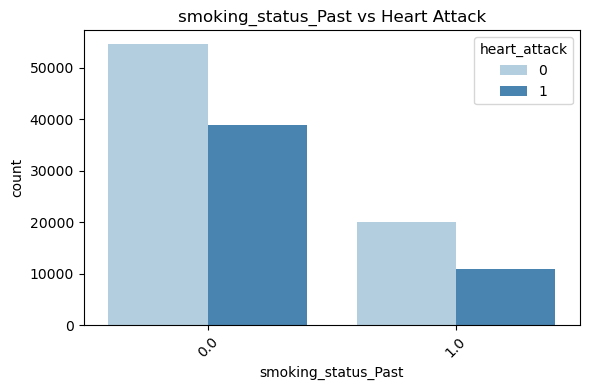

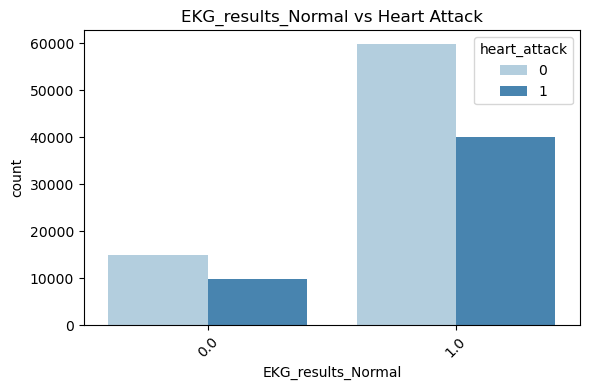

In [201]:
for col in ordinal_names + nominal_names:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=X_train_df, x=col, hue='heart_attack', palette='Blues')
    plt.title(f"{col} vs Heart Attack")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [202]:
df.dtypes

age                                 int64
gender                             object
region                             object
income_level                       object
hypertension                        int64
diabetes                            int64
cholesterol_level                   int64
obesity                             int64
waist_circumference                 int64
family_history                      int64
smoking_status                     object
alcohol_consumption                object
physical_activity                  object
dietary_habits                     object
air_pollution_exposure             object
stress_level                       object
sleep_hours                       float64
blood_pressure_systolic             int64
blood_pressure_diastolic            int64
fasting_blood_sugar                 int64
cholesterol_hdl                     int64
cholesterol_ldl                     int64
triglycerides                       int64
EKG_results                       

In [203]:
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, chi2, f_classif

In [204]:
df_fe = df.copy()

df_fe.head(20)

,age,gender,region,income_level,hypertension,diabetes,cholesterol_level,obesity,waist_circumference,family_history,...,blood_pressure_diastolic,fasting_blood_sugar,cholesterol_hdl,cholesterol_ldl,triglycerides,EKG_results,previous_heart_disease,medication_usage,participated_in_free_screening,heart_attack
0,60,Male,Rural,Middle,0,1,211,0,83,0,...,62,173,48,121,101,Normal,0,0,0,0
1,53,Female,Urban,Low,0,0,208,0,106,1,...,76,70,58,83,138,Normal,1,0,1,0
2,62,Female,Urban,Low,0,0,231,1,112,1,...,74,118,69,130,171,Abnormal,0,1,0,1
3,73,Male,Urban,Low,1,0,202,0,82,1,...,65,98,52,85,146,Normal,0,1,1,0
4,52,Male,Urban,Middle,1,0,232,0,89,0,...,75,104,59,127,139,Normal,1,0,1,1
5,52,Male,Urban,Middle,0,0,231,1,81,1,...,71,129,34,148,191,Normal,0,1,1,0
6,73,Female,Rural,Low,0,0,238,1,91,0,...,97,88,40,128,167,Normal,0,1,1,0
7,64,Female,Urban,Low,0,1,165,0,72,1,...,83,112,47,100,50,Normal,0,0,1,1
8,49,Female,Urban,Low,0,0,186,0,115,0,...,87,147,46,157,198,Abnormal,0,1,0,0
9,61,Male,Rural,Low,0,0,121,1,88,1,...,87,79,34,93,164,Normal,0,0,0,1


In [ ]:
# buat features baru
df_fe['cholesterol_ratio'] = (df_fe['cholesterol_ldl'] + df_fe['triglycerides']) / df_fe['cholesterol_hdl']
df_fe['avg_blood_pressure'] = (df_fe['blood_pressure_systolic'] + df_fe['blood_pressure_diastolic']) / 2

Encode Semua Ordinal

In [206]:
ordinal_map = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
if 'stress_level' in df_fe.columns:
    df_fe['stress_level'] = df_fe['stress_level'].map(ordinal_map)

In [207]:
ordinal_map = {
    'Low': 0,
    'Middle': 1,
    'High': 2
}
if 'income_level' in df_fe.columns:
    df_fe['income_level'] = df_fe['income_level'].map(ordinal_map)

In [208]:
ordinal_map = {
    'None': 0,
    'Moderate': 1,
    'High': 2
}

if 'alcohol_consumption' in df_fe.columns:  # perbaiki typo di sini
    df_fe['alcohol_consumption'] = df_fe['alcohol_consumption'].map(ordinal_map)

In [209]:
ordinal_map = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
if 'physical_activity' in df_fe.columns:
    df_fe['physical_activity'] = df_fe['physical_activity'].map(ordinal_map)

In [210]:
ordinal_map = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}
if 'air_pollution_exposure' in df_fe.columns:
    df_fe['air_pollution_exposure'] = df_fe['air_pollution_exposure'].map(ordinal_map)

In [211]:
df_fe['alcohol_consumption'].head()

0    1
1    1
2    1
3    1
4    1
Name: alcohol_consumption, dtype: int64

In [212]:
# --- Scaling untuk kolom numerik ---
numerical_cols = [
    'age', 'cholesterol_level', 'waist_circumference', 'sleep_hours',
    'blood_pressure_systolic', 'blood_pressure_diastolic', 'fasting_blood_sugar',
    'cholesterol_hdl', 'cholesterol_ldl', 'triglycerides',
    'cholesterol_ratio', 'avg_blood_pressure'
]


In [213]:
categorical_cols = [
    'gender', 'region', 'smoking_status', 'dietary_habits','EKG_results'
]

In [214]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output = False).set_output(transform = 'pandas')
df_cat = cat_encoder.fit_transform(df_fe[categorical_cols])

df_cat

,gender_Female,gender_Male,region_Rural,region_Urban,smoking_status_Current,smoking_status_Never,smoking_status_Past,dietary_habits_Healthy,dietary_habits_Unhealthy,EKG_results_Abnormal,EKG_results_Normal
0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
1,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0
2,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
3,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
158350,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
158351,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
158352,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
158353,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


In [215]:
df_fe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158355 entries, 0 to 158354
Data columns (total 30 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   age                             158355 non-null  int64  
 1   gender                          158355 non-null  object 
 2   region                          158355 non-null  object 
 3   income_level                    158355 non-null  int64  
 4   hypertension                    158355 non-null  int64  
 5   diabetes                        158355 non-null  int64  
 6   cholesterol_level               158355 non-null  int64  
 7   obesity                         158355 non-null  int64  
 8   waist_circumference             158355 non-null  int64  
 9   family_history                  158355 non-null  int64  
 10  smoking_status                  158355 non-null  object 
 11  alcohol_consumption             158355 non-null  int64  
 12  physical_activit

In [216]:
df_fe = pd.concat([df_cat, df_fe], axis = 1).drop(columns = categorical_cols)

In [217]:
df_fe.head(20)

,gender_Female,gender_Male,region_Rural,region_Urban,smoking_status_Current,smoking_status_Never,smoking_status_Past,dietary_habits_Healthy,dietary_habits_Unhealthy,EKG_results_Abnormal,...,fasting_blood_sugar,cholesterol_hdl,cholesterol_ldl,triglycerides,previous_heart_disease,medication_usage,participated_in_free_screening,heart_attack,cholesterol_ratio,avg_blood_pressure
0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,173,48,121,101,0,0,0,0,4.625000,87.5
1,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,70,58,83,138,1,0,1,0,3.810345,104.0
2,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,...,118,69,130,171,0,1,0,1,4.362319,95.0
3,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,98,52,85,146,0,1,1,0,4.442308,100.5
4,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,104,59,127,139,1,0,1,1,4.508475,101.0
5,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,129,34,148,191,0,1,1,0,9.970588,101.0
6,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,88,40,128,167,0,1,1,0,7.375000,112.5
7,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,112,47,100,50,0,0,1,1,3.191489,96.0
8,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,...,147,46,157,198,0,1,0,0,7.717391,118.5
9,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,...,79,34,93,164,0,0,0,1,7.558824,114.5


In [218]:
x = df_fe.drop('heart_attack', axis=1)
y = df_fe['heart_attack']

In [219]:
correlations = x.corrwith(y)
top_corr_features = correlations.abs().sort_values(ascending=False).head(10)
print("\nTop 10 Features by Pearson Correlation:")
print(top_corr_features)


Top 10 Features by Pearson Correlation:
previous_heart_disease    0.274775
hypertension              0.269261
diabetes                  0.194512
obesity                   0.171720
smoking_status_Current    0.170858
age                       0.105756
smoking_status_Never      0.098459
cholesterol_level         0.092611
fasting_blood_sugar       0.069826
waist_circumference       0.067883
dtype: float64


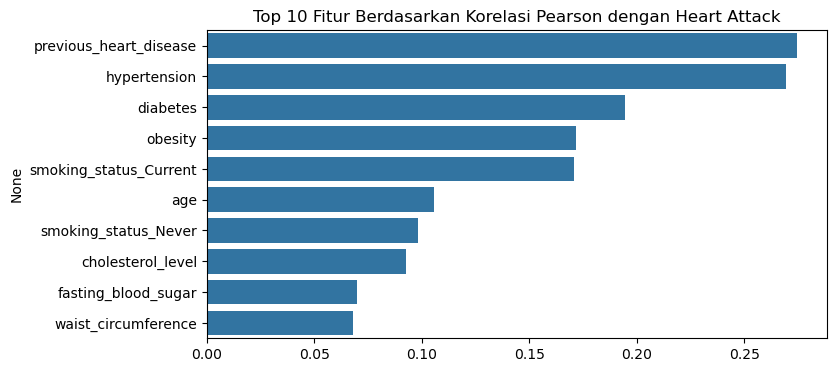

In [220]:
# Visualisasi Korelasi
plt.figure(figsize=(8, 4))
sns.barplot(x=top_corr_features.values, y=top_corr_features.index)
plt.title("Top 10 Fitur Berdasarkan Korelasi Pearson dengan Heart Attack")
plt.show()

In [221]:
df_fe['heart_attack'].value_counts()

heart_attack
0    94854
1    63501
Name: count, dtype: int64

Model Building

In [241]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.metrics import f1_score
import random

In [223]:
# Data splitting

random.seed(123)
df_train, df_test = train_test_split(df_fe, test_size = 0.3, random_state = 99)

print('df_fe: ', len(df_fe))
print('df train: ', len(df_train))
print('df test: ', len(df_test))

df_fe:  158355
df train:  110848
df test:  47507


In [224]:
# Predictor and Label

x_train = df_train.drop('heart_attack', axis = 1)
y_train = df_train['heart_attack']

x_test = df_test.drop('heart_attack', axis = 1)
y_test = df_test['heart_attack']

In [225]:
# Logistic Regression

lr = LogisticRegression()
lr.fit(x_train, y_train)

y_test_predict_lr = lr.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict_lr)
result = classification_report(y_test, y_test_predict_lr)
accuracy = accuracy_score(y_test, y_test_predict_lr)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)

Accuracy: 0.7235775780411308
[[23484  4991]
 [ 8141 10891]]
              precision    recall  f1-score   support

           0       0.74      0.82      0.78     28475
           1       0.69      0.57      0.62     19032

    accuracy                           0.72     47507
   macro avg       0.71      0.70      0.70     47507
weighted avg       0.72      0.72      0.72     47507



c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [275]:
# Logistic Regression with Hyperparameter Tuning

random.seed(123)

lr_parameters = {
    'C': randint(1, 100),
    'max_iter': randint(100, 1000)
}

lr_parameter_ht = RandomizedSearchCV(LogisticRegression(), lr_parameters, cv = 10, random_state = 49)
lr_parameter_ht.fit(x_train, y_train)

best_lr_parameters = lr_parameter_ht.best_estimator_

print(lr_parameter_ht.best_params_)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_

{'C': 97, 'max_iter': 950}


c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [276]:
lr_ht = LogisticRegression(C = 97, max_iter = 950)
lr_ht.fit(x_train, y_train)

y_test_predict_lr_ht = lr_ht.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict_lr_ht)
result = classification_report(y_test, y_test_predict_lr_ht)
accuracy = accuracy_score(y_test, y_test_predict_lr_ht)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)

Accuracy: 0.7311554086766161
[[23500  4975]
 [ 7797 11235]]
              precision    recall  f1-score   support

           0       0.75      0.83      0.79     28475
           1       0.69      0.59      0.64     19032

    accuracy                           0.73     47507
   macro avg       0.72      0.71      0.71     47507
weighted avg       0.73      0.73      0.73     47507



c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [228]:
# Decision Tree (before Hyperparameter Tuning)

dt_reg = DecisionTreeClassifier()
dt_reg.fit(x_train, y_train)

y_test_predict_dt = dt_reg.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict_dt)
result = classification_report(y_test, y_test_predict_dt)
accuracy = accuracy_score(y_test, y_test_predict_dt)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)


Accuracy: 0.6575452038646936
[[20314  8161]
 [ 8108 10924]]
              precision    recall  f1-score   support

           0       0.71      0.71      0.71     28475
           1       0.57      0.57      0.57     19032

    accuracy                           0.66     47507
   macro avg       0.64      0.64      0.64     47507
weighted avg       0.66      0.66      0.66     47507



In [229]:
# Hyperparameter Tuning for Decision Tree

random.seed(123)

dt_parameters = {
    'max_depth': randint(1, 1000),
    'min_samples_split': randint(2, 1000),
    'min_samples_leaf': randint(1, 1000),
}

dt_reg_ht = DecisionTreeClassifier()
parameters_random_search = RandomizedSearchCV(dt_reg_ht, param_distributions = dt_parameters, n_iter = 2000, cv = 10, n_jobs =- 1, random_state = 99)
parameters_random_search.fit(x_train, y_train)

best_dt_parameters = parameters_random_search.best_estimator_

best_dt_parameters.fit(x_train, y_train)

y_test_predict_dt_ht = best_dt_parameters.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict_dt_ht)
result = classification_report(y_test, y_test_predict_dt_ht)
accuracy = accuracy_score(y_test, y_test_predict_dt_ht)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)

c:\Users\marce\anaconda3\Lib\site-packages\numpy\ma\core.py:2820: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


Accuracy: 0.7352179678784179
[[23485  4990]
 [ 7589 11443]]
              precision    recall  f1-score   support

           0       0.76      0.82      0.79     28475
           1       0.70      0.60      0.65     19032

    accuracy                           0.74     47507
   macro avg       0.73      0.71      0.72     47507
weighted avg       0.73      0.74      0.73     47507



In [230]:
# Random Forest Before Hyperparameter Tuning

rf_reg = RandomForestClassifier()
rf_reg.fit(x_train, y_train)

y_test_predict_rf = rf_reg.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict_rf)
result = classification_report(y_test, y_test_predict_rf)
accuracy = accuracy_score(y_test, y_test_predict_rf)

print(f"Accuracy: {accuracy}")
print(cm)
print(result)

Accuracy: 0.7320394889174227
[[23418  5057]
 [ 7673 11359]]
              precision    recall  f1-score   support

           0       0.75      0.82      0.79     28475
           1       0.69      0.60      0.64     19032

    accuracy                           0.73     47507
   macro avg       0.72      0.71      0.71     47507
weighted avg       0.73      0.73      0.73     47507



In [231]:
# Hyperparamater Tuning for Random Forest

random.seed(123)

rf_parameters = {
    'n_estimators': randint(1, 250),
    'max_depth': randint(1, 250),
    'min_samples_split': randint(2, 250),
}

rf_reg_ht = RandomForestClassifier()

random_search_rf_parameter = RandomizedSearchCV(rf_reg_ht, param_distributions = rf_parameters, n_iter = 500, cv = 3, n_jobs = -1, random_state = 35)
random_search_rf_parameter.fit(x_train, y_train)

best_rf_parameters = random_search_rf_parameter.best_estimator_

best_rf_parameters.fit(x_train, y_train)

y_test_predict_rf_ht = best_rf_parameters.predict(x_test)
cm = confusion_matrix(y_test, y_test_predict_rf_ht)
result = classification_report(y_test, y_test_predict_rf_ht)
accuracy = accuracy_score(y_test, y_test_predict_rf_ht)
print(f"Accuracy: {accuracy}")
print(cm)
print(result)

Accuracy: 0.7362072957669397
[[23158  5317]
 [ 7215 11817]]
              precision    recall  f1-score   support

           0       0.76      0.81      0.79     28475
           1       0.69      0.62      0.65     19032

    accuracy                           0.74     47507
   macro avg       0.73      0.72      0.72     47507
weighted avg       0.73      0.74      0.73     47507



In [ ]:
# Voting Classifier

from sklearn.ensemble import VotingClassifier

estimators = [('Logistic Regression', LogisticRegression(C = 47, max_iter = 992, random_state = 90)), 
              ('Decision Tree', DecisionTreeClassifier(random_state = 90))]

vc_model_soft = VotingClassifier(estimators = estimators, voting = 'soft')
vc_model_soft.fit(x_train, y_train)
vc_prediction_soft = vc_model_soft.predict(x_test)

cm = confusion_matrix(y_test, vc_prediction_soft)
result = classification_report(y_test, vc_prediction_soft)
accuracy = accuracy_score(y_test, vc_prediction_soft)
print(f"Accuracy (Soft Voting): {accuracy}")
print(cm)
print(result)

vc_model_hard = VotingClassifier(estimators = estimators, voting = 'hard')
vc_model_hard.fit(x_train, y_train)
vc_prediction_hard = vc_model_hard.predict(x_test)

cm = confusion_matrix(y_test, vc_prediction_hard)
result = classification_report(y_test, vc_prediction_hard)
accuracy = accuracy_score(y_test, vc_prediction_hard)
print(f"Accuracy (Hard Voting): {accuracy}")
print(cm)
print(result)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy (Soft Voting): 0.6562190835034837
[[20219  8256]
 [ 8076 10956]]
              precision    recall  f1-score   support

           0       0.71      0.71      0.71     28475
           1       0.57      0.58      0.57     19032

    accuracy                           0.66     47507
   macro avg       0.64      0.64      0.64     47507
weighted avg       0.66      0.66      0.66     47507



c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy (Hard Voting): 0.7057696760477403
[[25496  2979]
 [10999  8033]]
              precision    recall  f1-score   support

           0       0.70      0.90      0.78     28475
           1       0.73      0.42      0.53     19032

    accuracy                           0.71     47507
   macro avg       0.71      0.66      0.66     47507
weighted avg       0.71      0.71      0.68     47507



In [235]:
# Bagging Classifier

from sklearn.ensemble import BaggingClassifier

# Logistic Regression

lr_bagging_model = BaggingClassifier(n_estimators = 200, estimator = LogisticRegression())
lr_bagging_model.fit(x_train, y_train)
lr_bagging_prediction = lr_bagging_model.predict(x_test)

cm = confusion_matrix(y_test, lr_bagging_prediction)
result = classification_report(y_test, lr_bagging_prediction)
accuracy = accuracy_score(y_test, lr_bagging_prediction)
print(f"Accuracy (Logistic Regression Bagging): {accuracy}")
print(cm)
print(result)

# Decision Tree

dt_bagging_model = BaggingClassifier(n_estimators = 200, estimator = DecisionTreeClassifier())
dt_bagging_model.fit(x_train, y_train)
dt_bagging_prediction = dt_bagging_model.predict(x_test)

cm = confusion_matrix(y_test, dt_bagging_prediction)
result = classification_report(y_test, dt_bagging_prediction)
accuracy = accuracy_score(y_test, dt_bagging_prediction)
print(f"Accuracy (Decision Tree Bagging): {accuracy}")
print(cm)
print(result)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_

Accuracy (Logistic Regression Bagging): 0.723809122866104
[[23573  4902]
 [ 8219 10813]]
              precision    recall  f1-score   support

           0       0.74      0.83      0.78     28475
           1       0.69      0.57      0.62     19032

    accuracy                           0.72     47507
   macro avg       0.71      0.70      0.70     47507
weighted avg       0.72      0.72      0.72     47507

Accuracy (Decision Tree Bagging): 0.726777106531669
[[23352  5123]
 [ 7857 11175]]
              precision    recall  f1-score   support

           0       0.75      0.82      0.78     28475
           1       0.69      0.59      0.63     19032

    accuracy                           0.73     47507
   macro avg       0.72      0.70      0.71     47507
weighted avg       0.72      0.73      0.72     47507



In [ ]:
# Adaboost

from sklearn.ensemble import AdaBoostClassifier

# Logistic Regression

lr_adaboost_model = AdaBoostClassifier(n_estimators = 200, estimator = lr, random_state = 30)
lr_adaboost_model.fit(x_train, y_train)
lr_adaboost_prediction = lr_adaboost_model.predict(x_test)

cm = confusion_matrix(y_test, lr_adaboost_prediction)
result = classification_report(y_test, lr_adaboost_prediction)
accuracy = accuracy_score(y_test, lr_adaboost_prediction)
print(f"Accuracy (Logistic Regression Adaboosting): {accuracy}")
print(cm)
print(result)

# Decision Tree (without hyperparameter tuning)

dt_adaboost_model = AdaBoostClassifier(n_estimators = 200, estimator = dt_reg, random_state = 30)
dt_adaboost_model.fit(x_train, y_train)
dt_adaboost_prediction = dt_adaboost_model.predict(x_test)

cm = confusion_matrix(y_test, dt_adaboost_prediction)
result = classification_report(y_test, dt_adaboost_prediction)
accuracy = accuracy_score(y_test, dt_adaboost_prediction)
print(f"Accuracy (Decision Tree Adaboosting): {accuracy}")
print(cm)
print(result)

# Decision Tree (with hyperparameter tuning)

dt_adaboost_parameters = {
    'n_estimators': randint(100, 1000),
    'learning_rate': uniform(0.05, 0.8),
}

dt_adaboost_random = RandomizedSearchCV(AdaBoostClassifier(), dt_adaboost_parameters, cv = 7, random_state = 30)
dt_adaboost_random.fit(x_train, y_train)
print(dt_adaboost_random.best_params_)

dt_adaboost_ht_model = AdaBoostClassifier(n_estimators = 913, estimator = dt_reg, learning_rate = 0.565314828854668, random_state = 30)
dt_adaboost_ht_model.fit(x_train, y_train)
dt_adaboost_ht_prediction = dt_adaboost_ht_model.predict(x_test)

cm = confusion_matrix(y_test, dt_adaboost_ht_prediction)
result = classification_report(y_test, dt_adaboost_ht_prediction)
accuracy = accuracy_score(y_test, dt_adaboost_ht_prediction)
print(f"Accuracy (Decision Tree Adaboosting with Hyperparameter Tuning): {accuracy}")
print(cm)
print(result)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale 

Accuracy (Logistic Regression Adaboosting): 0.7313238049129602
[[23474  5001]
 [ 7763 11269]]
              precision    recall  f1-score   support

           0       0.75      0.82      0.79     28475
           1       0.69      0.59      0.64     19032

    accuracy                           0.73     47507
   macro avg       0.72      0.71      0.71     47507
weighted avg       0.73      0.73      0.73     47507



c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Accuracy (Decision Tree Adaboosting): 0.6556928452649083
[[20228  8247]
 [ 8110 10922]]
              precision    recall  f1-score   support

           0       0.71      0.71      0.71     28475
           1       0.57      0.57      0.57     19032

    accuracy                           0.66     47507
   macro avg       0.64      0.64      0.64     47507
weighted avg       0.66      0.66      0.66     47507



c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
c:\Users\mar

{'learning_rate': 0.565314828854668, 'n_estimators': 913}


c:\Users\marce\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


Accuracy (Decision Tree Adaboosting with Hyperparameter Tuning): 0.6556928452649083
[[20228  8247]
 [ 8110 10922]]
              precision    recall  f1-score   support

           0       0.71      0.71      0.71     28475
           1       0.57      0.57      0.57     19032

    accuracy                           0.66     47507
   macro avg       0.64      0.64      0.64     47507
weighted avg       0.66      0.66      0.66     47507



In [237]:
# Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = GradientBoostingClassifier(n_estimators = 200, random_state = 50, learning_rate = 0.1)
gradient_boosting_model.fit(x_train, y_train)
gradient_boosting_prediction = gradient_boosting_model.predict(x_test)

cm = confusion_matrix(y_test, gradient_boosting_prediction)
result = classification_report(y_test, gradient_boosting_prediction)
accuracy = accuracy_score(y_test, gradient_boosting_prediction)
print(f"Accuracy (Gradient Boosting): {accuracy}")
print(cm)
print(result)

Accuracy (Gradient Boosting): 0.7372597722440903
[[23046  5429]
 [ 7053 11979]]
              precision    recall  f1-score   support

           0       0.77      0.81      0.79     28475
           1       0.69      0.63      0.66     19032

    accuracy                           0.74     47507
   macro avg       0.73      0.72      0.72     47507
weighted avg       0.73      0.74      0.74     47507



C:\Users\marce\AppData\Local\Temp\ipykernel_18796\4221713414.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x = models_used, y = f1_scores, palette = 'coolwarm')


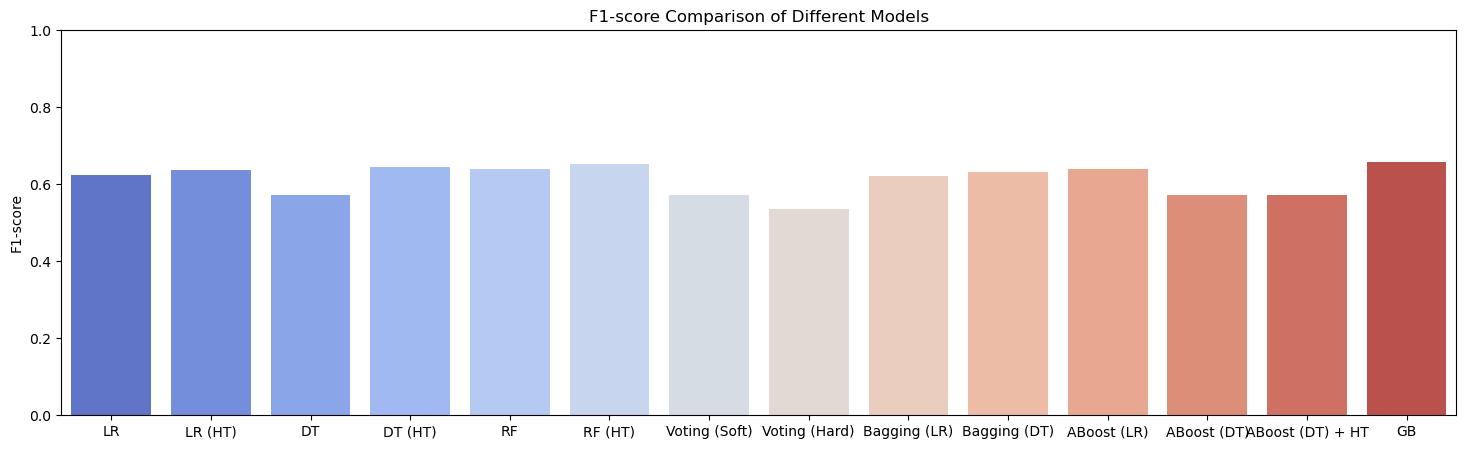

In [277]:
models_used = ['LR', 'LR (HT)', 
          'DT', 'DT (HT)',
          'RF', 'RF (HT)',
          'Voting (Soft)', 'Voting (Hard)',
          'Bagging (LR)', 'Bagging (DT)',
          'ABoost (LR)', 'ABoost (DT)',
          'ABoost (DT) + HT', 'GB']

f1_scores = [f1_score(y_test, y_test_predict_lr), f1_score(y_test, y_test_predict_lr_ht),
             f1_score(y_test, y_test_predict_dt), f1_score(y_test, y_test_predict_dt_ht),
             f1_score(y_test, y_test_predict_rf), f1_score(y_test, y_test_predict_rf_ht),
             f1_score(y_test, vc_prediction_soft), f1_score(y_test, vc_prediction_hard),
             f1_score(y_test, lr_bagging_prediction), f1_score(y_test, dt_bagging_prediction),
             f1_score(y_test, lr_adaboost_prediction), f1_score(y_test, dt_adaboost_prediction),
             f1_score(y_test, dt_adaboost_ht_prediction), f1_score(y_test, gradient_boosting_prediction)]

plt.figure(figsize=(18, 5))
sns.barplot(x = models_used, y = f1_scores, palette = 'coolwarm')
plt.ylabel('F1-score')
plt.title('F1-score Comparison of Different Models')
plt.ylim(0, 1)
plt.show()

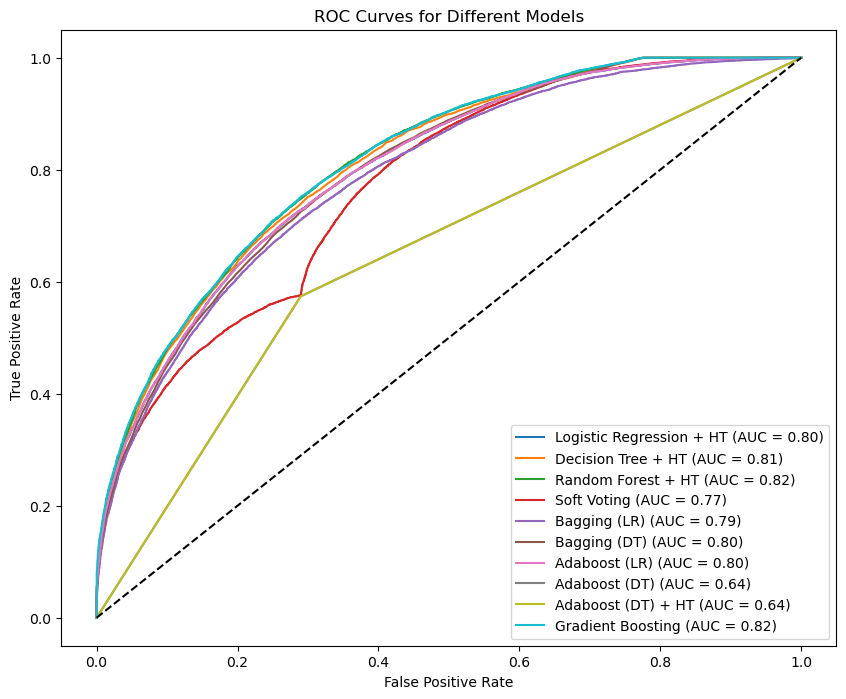

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob_lr_ht = best_lr_parameters.predict_proba(x_test)[:, best_lr_parameters.classes_.tolist().index(1)]
fpr_lr_ht, tpr_lr_ht, thresholds_lr_ht = roc_curve(y_test, y_prob_lr_ht, pos_label = 1)
auc_lr_ht = roc_auc_score(y_test, y_prob_lr_ht)

y_prob_dt_ht = best_dt_parameters.predict_proba(x_test)[:, best_dt_parameters.classes_.tolist().index(1)]
fpr_dt_ht, tpr_dt_ht, thresholds_dt_ht = roc_curve(y_test, y_prob_dt_ht, pos_label = 1)
auc_dt_ht = roc_auc_score(y_test, y_prob_dt_ht)

y_prob_rf_ht = best_rf_parameters.predict_proba(x_test)[:, best_rf_parameters.classes_.tolist().index(1)]
fpr_rf_ht, tpr_rf_ht, thresholds_rf_ht = roc_curve(y_test, y_prob_rf_ht, pos_label = 1)
auc_rf_ht = roc_auc_score(y_test, y_prob_rf_ht)

y_prob_vc_soft = vc_model_soft.predict_proba(x_test)[:, vc_model_soft.classes_.tolist().index(1)]
fpr_vc_soft, tpr_vc_soft, thresholds_vc_soft = roc_curve(y_test, y_prob_vc_soft, pos_label = 1)
auc_vc_soft = roc_auc_score(y_test, y_prob_vc_soft)

# Voting hard tidak menghitung probability sehingga tidak ada ROC / AUC curvenya

y_prob_bagging_lr = lr_bagging_model.predict_proba(x_test)[:, lr_bagging_model.classes_.tolist().index(1)]
fpr_bagging_lr, tpr_bagging_lr, thresholds_bagging_lr = roc_curve(y_test, y_prob_bagging_lr, pos_label = 1)
auc_bagging_lr = roc_auc_score(y_test, y_prob_bagging_lr)

y_prob_bagging_dt = dt_bagging_model.predict_proba(x_test)[:, dt_bagging_model.classes_.tolist().index(1)]
fpr_bagging_dt, tpr_bagging_dt, thresholds_bagging_dt = roc_curve(y_test, y_prob_bagging_dt, pos_label = 1)
auc_bagging_dt = roc_auc_score(y_test, y_prob_bagging_dt)

y_prob_ab_lr = lr_adaboost_model.predict_proba(x_test)[:, lr_adaboost_model.classes_.tolist().index(1)]
fpr_ab_lr, tpr_ab_lr, thresholds_ab_lr = roc_curve(y_test, y_prob_ab_lr, pos_label = 1)
auc_ab_lr = roc_auc_score(y_test, y_prob_ab_lr)

y_prob_ab_dt = dt_adaboost_model.predict_proba(x_test)[:, dt_adaboost_model.classes_.tolist().index(1)]
fpr_ab_dt, tpr_ab_dt, thresholds_ab_dt = roc_curve(y_test, y_prob_ab_dt, pos_label = 1)
auc_ab_dt = roc_auc_score(y_test, y_prob_ab_dt)

y_prob_ab_dt_ht = dt_adaboost_ht_model.predict_proba(x_test)[:, dt_adaboost_ht_model.classes_.tolist().index(1)]
fpr_ab_dt_ht, tpr_ab_dt_ht, thresholds_ab_dt_dt = roc_curve(y_test, y_prob_ab_dt_ht, pos_label = 1)
auc_ab_dt_ht = roc_auc_score(y_test, y_prob_ab_dt_ht)

y_prob_gb = gradient_boosting_model.predict_proba(x_test)[:, gradient_boosting_model.classes_.tolist().index(1)]
fpr_gb, tpr_gb, thresholds_gb = roc_curve(y_test, y_prob_gb, pos_label = 1)
auc_gb = roc_auc_score(y_test, y_prob_gb)

plt.figure(figsize=(10, 8))
plt.plot(fpr_lr_ht, tpr_lr_ht, label=f'Logistic Regression + HT (AUC = {auc_lr_ht:.2f})')
plt.plot(fpr_dt_ht, tpr_dt_ht, label=f'Decision Tree + HT (AUC = {auc_dt_ht:.2f})')
plt.plot(fpr_rf_ht, tpr_rf_ht, label=f'Random Forest + HT (AUC = {auc_rf_ht:.2f})')
plt.plot(fpr_vc_soft, tpr_vc_soft, label=f'Soft Voting (AUC = {auc_vc_soft:.2f})')
plt.plot(fpr_bagging_lr, tpr_bagging_lr, label=f'Bagging (LR) (AUC = {auc_bagging_lr:.2f})')
plt.plot(fpr_bagging_dt, tpr_bagging_dt, label=f'Bagging (DT) (AUC = {auc_bagging_dt:.2f})')
plt.plot(fpr_ab_lr, tpr_ab_lr, label=f'Adaboost (LR) (AUC = {auc_ab_lr:.2f})')
plt.plot(fpr_ab_dt, tpr_ab_dt, label=f'Adaboost (DT) (AUC = {auc_ab_dt:.2f})')
plt.plot(fpr_ab_dt_ht, tpr_ab_dt_ht, label=f'Adaboost (DT) + HT (AUC = {auc_ab_dt_ht:.2f})')
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {auc_gb:.2f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curves for Different Models')
plt.legend()
plt.show()
